# Train

Train the U-Net surrogate on the generated dataset. Pick a profile from `src/erosion_sim/config.py`,
optionally override some of its fields, and run. The best checkpoint (lowest validation loss) is
saved to `artifacts/unet-<profile>.pt`. The latest state is saved at every validation to
`artifacts/unet-<profile>-last.pt`; set `RESUME = True` to continue an interrupted run from it. Look at the results in `notebooks/evaluate.ipynb`, which
loads the checkpoint without retraining.

Profiles:

- `overfit`: memorize 10 pairs. A check that the pipeline works; about 1.5 minutes.
- `fixed_dt`: one elapsed time (10,000 yr), runs without uplift.
- `variable_dt`: every elapsed time, runs without uplift, one pass over every pair.

The loss is the MSE (mean squared error) of the normalized change. **Skill** is
`1 - MSE / MSE(no change)`: 0 means no better than predicting no change, 1 is perfect.

In [1]:
from dataclasses import asdict

from erosion_sim.config import PROFILES
from erosion_sim.train import train

In [2]:
PROFILE = "overfit"
OVERRIDES = {}  # for example {"steps": 5_000, "lr": 1e-4}
RESUME = False  # continue from artifacts/unet-<PROFILE>-last.pt

for key, value in {**asdict(PROFILES[PROFILE]), **OVERRIDES}.items():
    print(f"{key:<18} {value}")

profile            overfit
data_profile       full
runs               ()
lags               None
scale              fitted
max_train_samples  10
channels           (32, 64, 128, 256)
blocks             1
emb_dim            256
attention          True
batch_size         10
lr                 0.001
weight_decay       0.0
steps              2000
warmup_steps       50
eval_every         500
val_samples        256
log_every          100
num_workers        2
compile            False
bf16               True
seed               0


overfit: 8,428,193 parameters, 10 training pairs, 256 validation pairs, device cuda


step 100/2000  train loss 0.3024  lr 9.98e-04  61 samples/s


step 200/2000  train loss 0.0330  lr 9.85e-04  99 samples/s


step 300/2000  train loss 0.0130  lr 9.60e-04  125 samples/s


step 400/2000  train loss 0.0066  lr 9.23e-04  144 samples/s


...

step 1700/2000  train loss 0.0009  lr 5.73e-05  214 samples/s


step 1800/2000  train loss 0.0008  lr 2.57e-05  216 samples/s


step 1900/2000  train loss 0.0008  lr 6.47e-06  218 samples/s


step 2000/2000  train loss 0.0008  lr 0.00e+00  219 samples/s


  validation loss 0.2838  skill vs no change 0.735


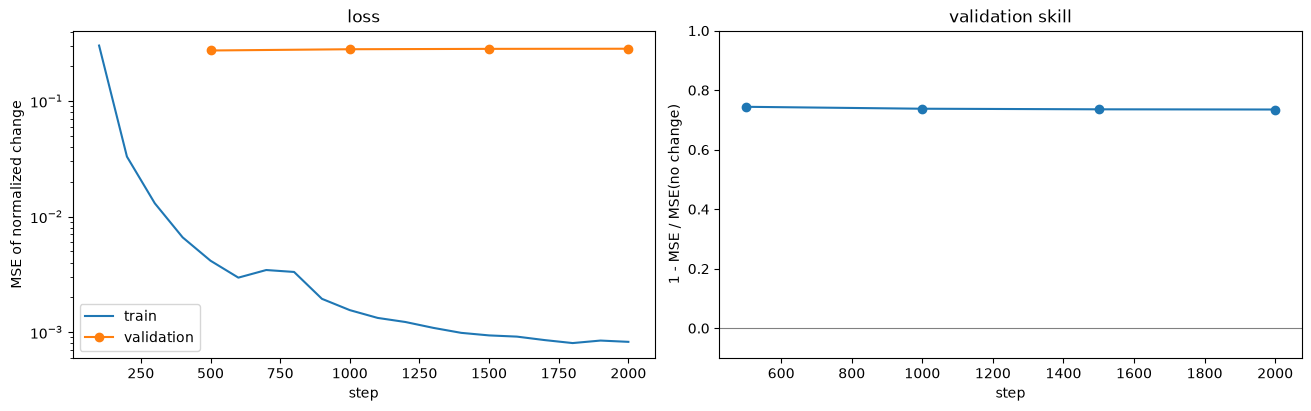

best checkpoint: /home/jay/Work/repos/erosion-sim-modeling/artifacts/unet-overfit.pt  (1.5 min)


In [3]:
history = train(PROFILES[PROFILE], resume=RESUME, **OVERRIDES)
print(f"best checkpoint: {history['checkpoint']}  ({history['seconds'] / 60:.1f} min)")